# 05. Pembentukan Kamus Semantik *Frame* & Ekstraksi Ganda Fitur SVM

Notebook ini menjalankan **Tahap 5 metodologi penelitian**:
1. **Pembentukan Kamus Semantik *Frame* per Kategori**: menghitung rata-rata bobot TF-IDF frasa *bigram* & *trigram* (*Bigram & Trigram*) dari `data/basic_articles_dataset.csv` untuk masing-masing 11 kategori dan menyimpannya ke `results/lexicons/tfidf_top1000/`.
2. **Ekstraksi Ganda Medan Makna & Semantik *Frame* dengan Model SVM Terlatih**: memuat model SVM yang telah dilatih pada **Notebook 04** (`models/svm_frame_semantik.joblib` & `models/svm_medan_makna.joblib`) serta 11 artikel uji dari `basic_articles_dataset.csv` (`results/stats/sample_11_test_articles.csv`) untuk menganalisis:
   - Prediksi kategori ganda & skor *Sigmoid* lintas 11 kelas.
   - Bobot TF-IDF dan koefisien hyperplane SVM positif (`+`) vs negatif (`-`) pada kata **Medan Makna ** maupun frasa **Semantik *Frame* **.
   - Visualisasi *WordCloud* dan grafik batang fitur teratas ke `results/figures/`.


In [1]:
import sys
from pathlib import Path

# Resolve root repositori secara relatif
cwd = Path.cwd().resolve()
REPO_ROOT = cwd if (cwd / "src" / "arabic_news").exists() else cwd.parent
SRC_DIR = REPO_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print(f"Repository root: {REPO_ROOT.name}")

from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from wordcloud import WordCloud

from arabic_news.config import (
    FIGURES_DIR,
    LABELS,
    LABELS_ID,
    LEXICONS_DIR,
    RANDOM_SEED,
    STATS_DIR,
    resolve_data_file,
)
from arabic_news.evaluation import select_one_sample_per_category, split_dataset_85_10_5
from arabic_news.features import extract_ngrams_with_weights_by_label
from arabic_news.models import analyze_article_dual_svm, load_compact_svm_bundles
from arabic_news.preprocessing import (
    load_stopwords,
    preprocess_text,
    reshape_arabic_for_plot,
)
from arabic_news.visualization import find_arabic_font_path

plt.rcParams["figure.dpi"] = 120


Repository root: arabic_news_classification


## 5.1 Pembentukan Kamus Semantik *Frame* TF-IDF (*Bigram & Trigram*) per Kategori

Menghitung rata-rata bobot TF-IDF frasa bigram dan trigram langsung dari `basic_articles_dataset.csv` dan menyimpan Top-1000 frasa per kategori ke `results/lexicons/tfidf_top1000/`.


,Label,Kategori,Frasa Frame #1,Rata-rata Bobot TF-IDF #1,Frasa Frame #2,Frasa Frame #3
0,1,أمن (Keamanan),مصدر في,0.005089,مجلس النواب,في شرطة
1,2,اقتصاد (Ekonomi),صرف الدولار,0.006454,مليون دينار,إلى دولار
2,3,تكنولوجيا (Teknologi),في العالم,0.011049,تعرف على,الهواتف في
3,4,ثقافة (Budaya),نجيب محفوظ,0.019966,في المسرح,مسرحه الفقير
4,5,دوليات (Internasional),قطاع غزة,0.005009,دولة قطر,إلى أن
5,6,رياضة (Olahraga),كأس العالم,0.009559,المزيد نوفمبر,رئيس الاتحاد
6,7,سياحة (Travel / Pariwisata),موعد قيامه,0.029888,موعد قيامه الساعة,قيامه الساعة
7,8,سياسة (Politik),مجلس النواب,0.008184,رئيس الوزراء,السومرية نيوز
8,9,صحة (Kesehatan),بفيروس كورونا,0.007119,كورونا في,وزارة الصحة
9,10,علم (Sains),إلى أن,0.003640,يمكن أن,أكثر من


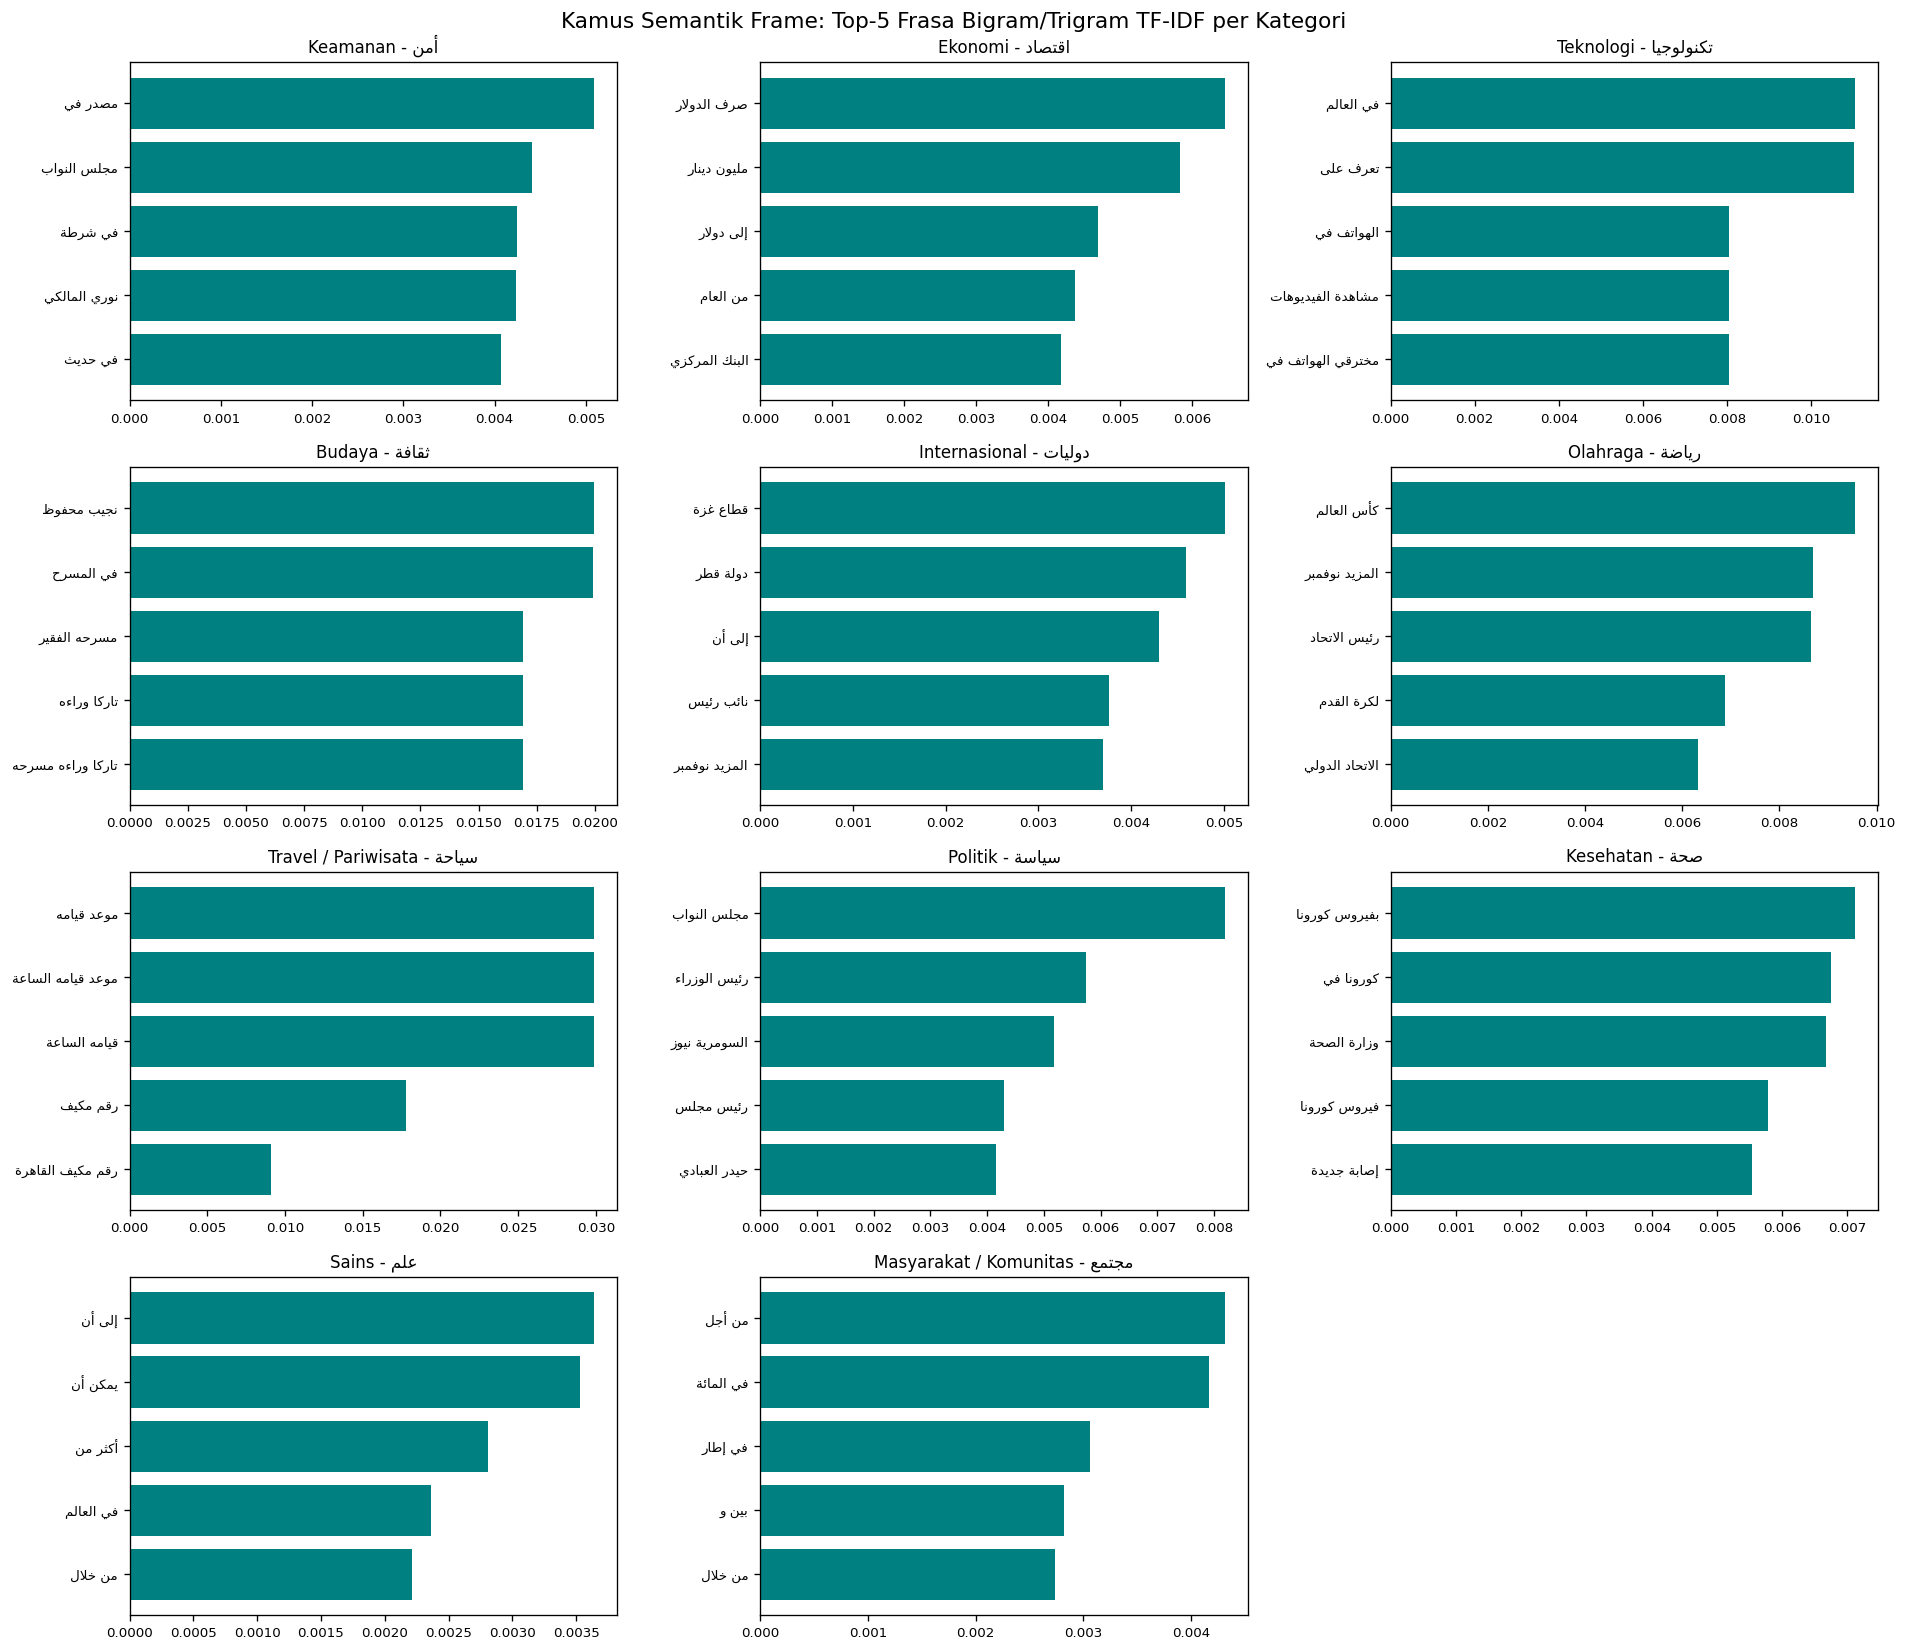

Kamus TF-IDF Semantik Frame tersimpan ke results/lexicons/tfidf_top1000/


In [2]:
basic_csv = resolve_data_file("basic_articles_dataset.csv")
df_basic = pd.read_csv(basic_csv, low_memory=False).dropna(subset=["text"]).copy()
df_basic["label"] = pd.to_numeric(df_basic["label"], errors="coerce")
df_basic = df_basic.dropna(subset=["label"]).copy()
df_basic["label"] = df_basic["label"].astype(int)
df_basic["frame_text"] = df_basic["text"].astype(str).apply(lambda t: preprocess_text(t, stopwords=None))

tfidf_dir = LEXICONS_DIR / "tfidf_top1000"
tfidf_dir.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

lexicon_tables = {}
summary_rows = []
for cid, cname in LABELS.items():
    top1000_df = extract_ngrams_with_weights_by_label(
        df_basic, category_id=cid, text_column="frame_text", ngram_range=(2, 3), top_n=1000
    )
    top1000_df.to_csv(tfidf_dir / f"ngram_tfidf_weights_{cname}.csv", index=False, encoding="utf-8")
    lexicon_tables[cid] = top1000_df.head(10)
    summary_rows.append({
        "Label": cid,
        "Kategori": f"{cname} ({LABELS_ID[cid]})",
        "Frasa Frame #1": top1000_df.iloc[0]["N-gram"],
        "Rata-rata Bobot TF-IDF #1": float(top1000_df.iloc[0]["TF-IDF Weight"]),
        "Frasa Frame #2": top1000_df.iloc[1]["N-gram"],
        "Frasa Frame #3": top1000_df.iloc[2]["N-gram"],
    })

display(pd.DataFrame(summary_rows))

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes_flat = axes.flatten()
for idx, (cid, cname) in enumerate(LABELS.items()):
    ax = axes_flat[idx]
    top5 = lexicon_tables[cid].head(5).iloc[::-1]
    ax.barh([reshape_arabic_for_plot(p) for p in top5["N-gram"]], top5["TF-IDF Weight"], color="teal")
    ax.set_title(f"{LABELS_ID[cid]} - {reshape_arabic_for_plot(cname)}", fontsize=10)
    ax.tick_params(axis="both", labelsize=8)
axes_flat[-1].axis("off")
fig.suptitle("Kamus Semantik Frame: Top-5 Frasa Bigram/Trigram TF-IDF per Kategori", fontsize=13)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "frame_lexicon_grid.png", dpi=150)
plt.show()
print("Kamus TF-IDF Semantik Frame tersimpan ke results/lexicons/tfidf_top1000/")


## 5.2 Ekstraksi Ganda Medan Makna & Semantik *Frame* + Koefisien SVM pada 11 Artikel Uji

Memuat model terlatih hasil **Notebook 04** dari `models/` dan menganalisis ke-11 artikel uji yang diambil dari split uji `basic_articles_dataset.csv`.


In [3]:
bundles = load_compact_svm_bundles()
if "medan_makna" not in bundles or "frame_semantik" not in bundles:
    raise FileNotFoundError(
        "Model terlatih belum ditemukan di models/. Jalankan Notebook 04_model_training_and_evaluation.ipynb terlebih dahulu."
    )

sample_path = STATS_DIR / "sample_11_test_articles.csv"
if sample_path.exists():
    sample_11 = pd.read_csv(sample_path)
else:
    _, _, te_f_df = split_dataset_85_10_5(df_basic, random_state=RANDOM_SEED)
    sample_11 = select_one_sample_per_category(te_f_df, random_state=RANDOM_SEED)

stopwords_list = load_stopwords()
dual_rows = []
dual_details = {}

for _, row in sample_11.sort_values("label").iterrows():
    cid = int(row["label"])
    dual = analyze_article_dual_svm(str(row["text"]), bundles=bundles, stopwords=stopwords_list)
    dual_details[cid] = (row, dual)
    m_res = dual["medan_makna"]
    f_res = dual["frame_semantik"]

    dual_rows.append({
        "Label": cid,
        "Kategori Asli": f"{LABELS[cid]} ({LABELS_ID[cid]})",
        "Pred. Medan Makna": m_res["predicted_category"],
        "Pred. Semantik Frame": f_res["predicted_category"],
        "Cocok?": (m_res["predicted_label"] == cid) and (f_res["predicted_label"] == cid),
        "Skor Sigmoid Frame (%)": round(f_res["category_scores"][0]["sigmoid_percent"], 2),
        "Top Medan (+Coef)": m_res["positive_coefs"][0]["term"] if m_res["positive_coefs"] else "-",
        "Top Frame (TF-IDF)": f_res["features_by_tfidf"][0]["term"] if f_res["features_by_tfidf"] else "-",
    })

dual_df = pd.DataFrame(dual_rows)
display(dual_df)
print(f"Akurasi kombinasi pada 11 artikel uji: {dual_df['Cocok?'].mean() * 100:.2f}%")


,Label,Kategori Asli,"Pred. Medan (1,1)","Pred. Frame (2,3)",Cocok?,Skor Sigmoid Frame (%),Top Medan (+Coef),Top Frame (TF-IDF)
0,1,أمن (Keamanan),أمن,أمن,True,90.17,العراقية,المسيحي في
1,2,اقتصاد (Ekonomi),اقتصاد,اقتصاد,True,95.05,سرايا,بدء العام
2,3,تكنولوجيا (Teknologi),تكنولوجيا,تكنولوجيا,True,97.76,آبل,كلمة مرور
3,4,ثقافة (Budaya),ثقافة,ثقافة,True,73.10,المسرح,يغادر تاركا وراءه
4,5,دوليات (Internasional),دوليات,دوليات,True,98.38,إعلام,العاصمة الأوكرانية
5,6,رياضة (Olahraga),رياضة,رياضة,True,97.40,صنعت,المدرب الوطني
6,7,سياحة (Travel / Pariwisata),سياحة,سياحة,True,89.91,الطيران,مطار الدقم
7,8,سياسة (Politik),سياسة,سياسة,True,88.09,نيوز,الحكيم رئيسا
8,9,صحة (Kesehatan),صحة,صحة,True,91.50,كورونا,مليون إصابة
9,10,علم (Sains),علم,علم,True,72.04,للإنسان,من الصداع


Akurasi kombinasi pada 11 artikel uji: 100.00%


## 5.3 Visualisasi Rinci Koefisien SVM, Skor Sigmoid, & *WordCloud* Artikel Sampel Uji


Rincian TF-IDF & Koefisien SVM Medan Makna (Artikel Uji Olahraga):


,term,n_tokens,tfidf_weight,svm_coef,contribution
0,آدم,1,0.385635,0.156676,0.060420
1,قاسيا,1,0.282887,0.046258,0.013086
2,الفريق,1,0.249948,1.102987,0.275689
3,المدرب,1,0.208596,2.309674,0.481789
4,قرار,1,0.170368,-0.640779,-0.109168
5,يوسف,1,0.168912,-0.376645,-0.063620
6,النادي,1,0.151843,1.740905,0.264344
7,مهامه,1,0.148038,0.140884,0.020856
8,الخريطيات,1,0.144615,0.507060,0.073329
9,منصور,1,0.134604,0.980464,0.131975


,term,n_tokens,tfidf_weight,svm_coef,contribution
0,المدرب الوطني,2,0.188925,0.214881,0.040596
1,على النادي,2,0.184739,0.273547,0.050535
2,النادي الذي,2,0.180672,0.330907,0.059786
3,مثله مثل أي,3,0.112512,0.003791,0.000427
4,أمس وذلك,2,0.109484,0.165304,0.018098
5,يتوقع فيه,2,0.107861,-0.005234,-0.000565
6,لم يعد يحتمل,3,0.107861,-0.003051,-0.000329
7,يعد يحتمل,2,0.107135,-0.003031,-0.000325
8,أن تدريبات,2,0.104647,0.145729,0.015250
9,الأهلي بعد,2,0.103594,-0.077763,-0.008056


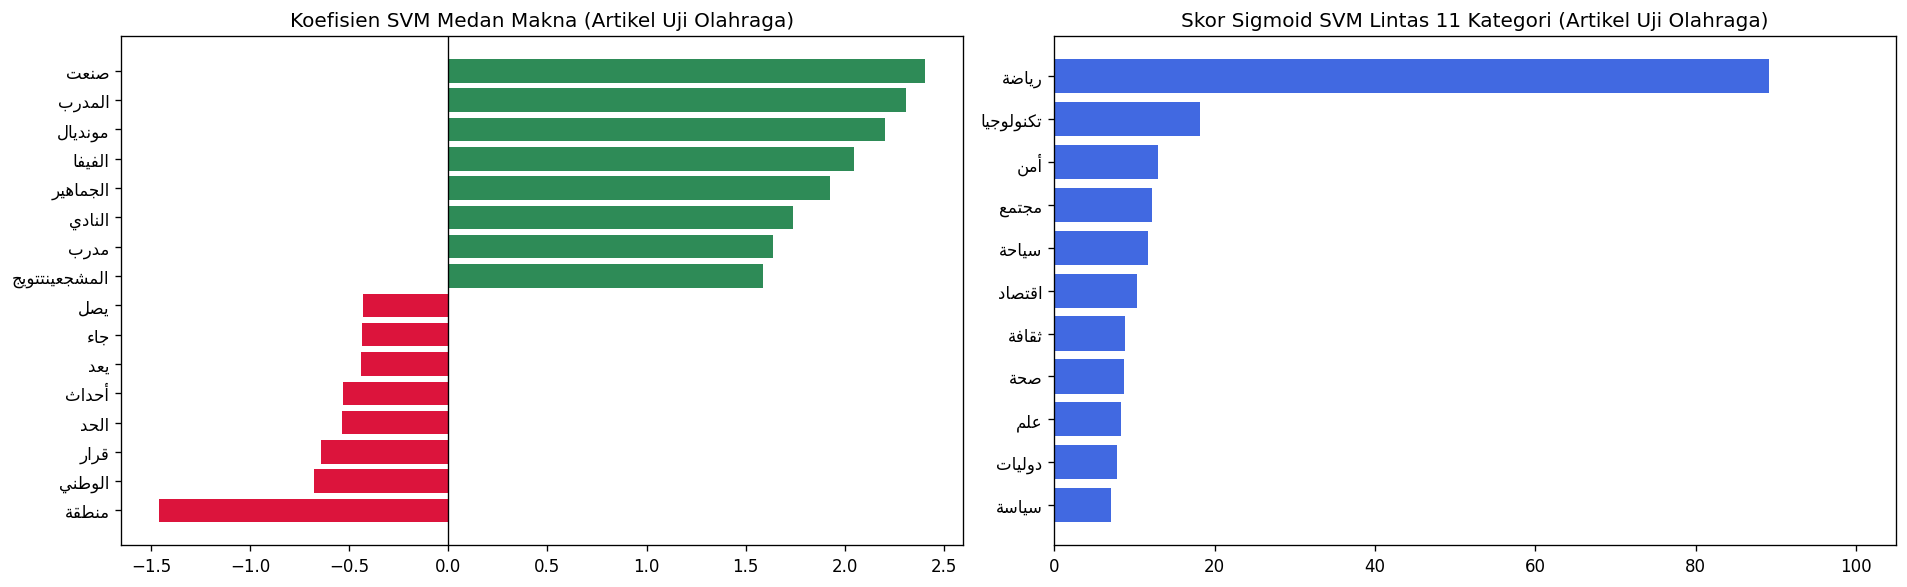

Font Arab aktif: arial.ttf


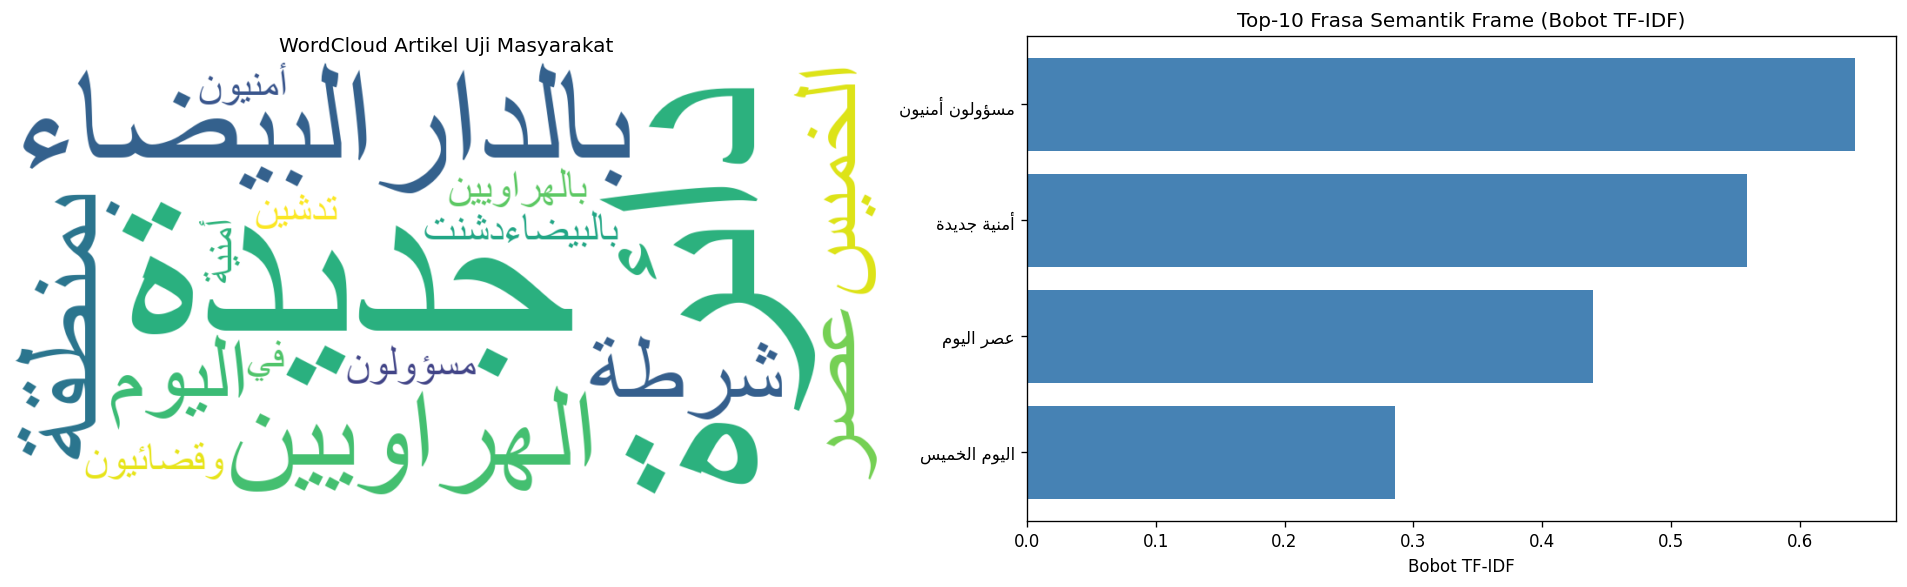

In [4]:
# Contoh visualisasi rinci pada sampel Olahraga (label 6) dan Masyarakat (label 11)
sport_row, sport_dual = dual_details[6]
sport_medan = sport_dual["medan_makna"]

print("Rincian TF-IDF & Koefisien SVM Medan Makna (Artikel Uji Olahraga):")
display(pd.DataFrame(sport_medan["features_by_tfidf"][:10]))
display(pd.DataFrame(sport_dual["frame_semantik"]["features_by_tfidf"][:10]))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
top_coefs = sorted(
    sport_medan["positive_coefs"][:8] + sport_medan["negative_coefs"][:8],
    key=lambda d: d["svm_coef"],
)
axes[0].barh(
    [reshape_arabic_for_plot(d["term"]) for d in top_coefs],
    [d["svm_coef"] for d in top_coefs],
    color=["seagreen" if d["svm_coef"] > 0 else "crimson" for d in top_coefs],
)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Koefisien SVM Medan Makna (Artikel Uji Olahraga)")

scores_sorted = sorted(sport_medan["category_scores"], key=lambda x: x["sigmoid_percent"])
axes[1].barh(
    [reshape_arabic_for_plot(s["category"]) for s in scores_sorted],
    [s["sigmoid_percent"] for s in scores_sorted],
    color="royalblue",
)
axes[1].set_xlim(0, 105)
axes[1].set_title("Skor Sigmoid SVM Lintas 11 Kategori (Artikel Uji Olahraga)")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "sport_sample_svm_analysis.png", dpi=150)
plt.show()

# WordCloud + Top-10 Frasa Semantik Frame pada sampel Masyarakat (label 11)
soc_row, soc_dual = dual_details[11]
soc_frame = soc_dual["frame_semantik"]
font_path = find_arabic_font_path()
print(f"Font Arab aktif: {Path(font_path).name if font_path else 'default'}")

fig2, axes2 = plt.subplots(1, 2, figsize=(16, 5))
wc = WordCloud(font_path=font_path, width=1000, height=500, background_color="white").generate(
    reshape_arabic_for_plot(soc_frame["cleaned_text"])
)
axes2[0].imshow(wc, interpolation="bilinear")
axes2[0].axis("off")
axes2[0].set_title("WordCloud Artikel Uji Masyarakat")

top10_f = soc_frame["features_by_tfidf"][:10][::-1]
axes2[1].barh(
    [reshape_arabic_for_plot(d["term"]) for d in top10_f],
    [d["tfidf_weight"] for d in top10_f],
    color="steelblue",
)
axes2[1].set_title("Top-10 Frasa Semantik Frame (Bobot TF-IDF)")
axes2[1].set_xlabel("Bobot TF-IDF")
plt.tight_layout()
fig2.savefig(FIGURES_DIR / "society_sample_wordcloud_frame.png", dpi=150)
plt.show()
